[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/4_subspace_alignment.ipynb)

# Subspace alignment across encoders and areas

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the subspace alignment of the top-k eigenvectors of G(x) and J(x), for models fitted to the same area (solid) or the same model fitted to different areas (dashed), averaged over images (paper Fig. 4D-E).

* **Requirements**: the datasets and checkpoints (see the README) and GPUs; Modal is optional.

* **Time**: 1 min for the quick local test. Estimating G(x) takes about 15 s per image and configuration, split over workers.

<details><summary>Details</summary>

* **Steps**: (1) estimate G(x) and J(x) for the test images of every (encoder, area) configuration, (2) alignment between configurations, (3) plot. The G(x) estimation is the expensive step; the images are independent, so they are split over workers (GPUs) without changing any result. No DDP/FSDP is needed: nothing is communicated between GPUs.
* The supporting functions are in `multigeom.pipeline.distribute` and `multigeom.pipeline.alignment`; the plot is `figures/alignment.py`. This notebook only sets parameters and calls them.

</details>

## 1. Example scenarios

The parameters are set in the next cell: `CONFIGS`, `N_IMAGES`, `BACKEND`, `DEVICE` and `NUM_WORKERS` (plus `GPU_TYPE` and `MAX_COST_USD` for Modal). Four typical scenarios and the values to give them:

| Scenario | `CONFIGS` | `N_IMAGES` | `BACKEND` | `DEVICE` | `NUM_WORKERS` |
|---|---|---|---|---|---|
| quick check on this machine | `("inception", "V1")` | 3 | `"local"` | `"gpu"` | 1 |
| one configuration, all images, this machine | `("inception", "V1")` | 200 | `"local"` | `"gpu"` | 1 |
| one configuration, all images, Modal | `("inception", "V1")` | 200 | `"modal"` | `"gpu"` | 10 |
| all configurations, all images, Modal | `sa.ALL_CONFIGS` (inception and resnet50 x V1 and V4) | 200 | `"modal"` | `"gpu"` | 10 |

* `CONFIGS` is one `(encoder, area)` pair or a list of them. `NUM_WORKERS` workers run in parallel, one GPU (or one CPU process) each; on this machine it is capped at the number of GPUs present, and a Modal Starter plan allows 10 at once.
* The alignment compares two configurations, so with a single one this notebook estimates G(x) and J(x) but cannot plot Fig. 4D-E: add a second one (for example `[("inception", "V1"), ("inception", "V4")]`) to get the dashed V1-vs-V4 curve.
* `DEVICE = "cpu"` works but is slow (about 15 min per image on a 32-core CPU, using all cores), so there is no CPU scenario here.
* On Modal you pay for GPU time. The estimate printed below uses third-party prices and is a guide, not a bill; the launch is refused if it exceeds `MAX_COST_USD`.

In [1]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root (the folder containing environment.yml): data/ and runs/ are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))      # the figures/ folder of this repository

# import custom package
from multigeom.utils import show_figure
from figures.alignment import plot_alignment
from multigeom.pipeline import alignment, distribute as sa
importlib.reload(sa)      # update the module without restarting the kernel

# parameters (see the table above for examples)
CONFIGS = ("inception", "V1")      # (encoder, area), or a list of them; sa.ALL_CONFIGS = all four
N_IMAGES = 3                       # first N test images (the paper uses 200)
BACKEND = "local"                  # "local" (this machine) | "modal" (serverless GPUs)
DEVICE = "gpu"                     # "gpu" | "cpu" (Modal: "gpu")
NUM_WORKERS = 1                    # parallel workers (local GPU: at most the GPUs present; Modal Starter plan: 10)
GPU_TYPE = "A100"                  # Modal only
MAX_COST_USD = 2.0                 # Modal only: the launch is refused above this estimate

scenario = sa.Scenario(configs=CONFIGS, n_images=N_IMAGES, backend=BACKEND, device=DEVICE,
                       num_workers=NUM_WORKERS, gpu_type=GPU_TYPE, max_cost_usd=MAX_COST_USD)

RUN = True                       # False: only print the estimate. True: launch the computation.
RESTART = True                   # True: first delete the per-image results of this scenario, to recompute them from scratch

print(scenario)
sa.print_estimate(scenario)             # what this would take (and cost, on Modal)

Scenario(configs=(('inception', 'V1'),), n_images=3, backend='local', device='gpu', num_workers=1, gpu_type='A100', seconds_per_image=None, startup_s=15.0, max_cost_usd=2.0)
3 image computations on local, 1 GPU worker(s): ~1.0 GPU-min in total, ~1.0 min wall-clock
CPU times: user 2.97 s, sys: 103 ms, total: 3.07 s
Wall time: 687 ms


CostEstimate(n_computations=3, n_workers=1, gpu_seconds=60.0, wall_seconds=60.0, cost_usd=None)

## 2. Estimate G(x) and J(x) for every image and configuration

* **local**: one detached process per GPU (or one on the CPU). It keeps running if the notebook kernel dies, and relaunching continues where it stopped (finished images are skipped). Logs are in `runs/logs/`. Several processes on a single GPU are slower than one, so `num_gpus` is capped at the number of GPUs present.
* **modal**: needs `pip install modal` and `modal token new` once. The checkpoints and test images are uploaded to a Modal volume the first time, one container with one GPU runs each worker's shards, and the results are downloaded to `runs/per_image/`. The progress bar counts the finished images on the volume (each container saves the volume every 30 s, so the bar can lag by up to about that long). Interrupting the kernel cancels the Modal calls. Not exercised by the repository's automated tests (they need your Modal account).
* **Restart from scratch**: the estimation skips the images that already exist, so to recompute them set `RESTART = True` (above) before launching. This deletes only the per-image files of this scenario's configurations and first `n_images` images (locally, and on the Modal volume for the Modal backend), never checkpoints. To stop running workers, interrupt the wait cell or call `sa.stop_workers()`.


In [2]:
%%time

if not RUN:
    print("RUN is False: nothing was started. Set RUN = True above to launch.")
else:

    sa.check_budget(scenario, run=True)
    device, num_workers = sa.resolve_workers(scenario)
    if RESTART:    # the estimation skips images that exist, so a restart from scratch means deleting them first
        sa.clear_results(scenario.configs, scenario.n_images)
        if scenario.backend == "modal":
            sa.modal_clear(scenario.configs, scenario.n_images)
    workers = sa.make_shards(scenario.configs, scenario.n_images, num_workers, runs_dir="runs")   # images already done are left out
    print(f"{len(workers)} worker(s):", [[(s.encoder, s.area, s.start, s.end) for s in w] for w in workers])

    if not workers:
        procs = []
        print("All images are already computed: nothing to launch.")
    elif scenario.backend == "local":
        procs = sa.launch_local(workers, use_gpu=device == "gpu")
        for p in procs:
            print(p)
    else:
        sa.modal_upload(scenario.configs)
        sa.launch_modal(workers, gpu_type=scenario.gpu_type)
        sa.modal_download(scenario.configs, scenario.n_images)

3 image computations on local, 1 GPU worker(s): ~1.0 GPU-min in total, ~1.0 min wall-clock
deleted 3 per-image file(s)
1 worker(s): [[('inception', 'V1', 0, 3)]]
{'worker': 0, 'pid': 1431182, 'device': 'cuda:0', 'log': '/home/steeve/steeve/idv/code/multigeom-tutorials/runs/logs/worker0.log'}
CPU times: user 1.15 ms, sys: 13 ms, total: 14.1 ms
Wall time: 18.9 ms


### 2.1. Wait for the local workers (local backend)

The workers run in the background, so the next cells would find the results missing or incomplete. This cell waits for them and shows a progress bar (images done out of the total, elapsed time and an estimate of the time left; it refreshes every 15 s and an image takes between 15 s and 15 min), which blocks the notebook for that time (about 15 min per image on the CPU, about 15 s per image on a recent GPU). **Interrupting the kernel (the stop button) stops the workers too**; the images already finished are kept and launching again resumes from there. To only stop waiting and leave the workers running, pass `stop_on_interrupt=False`. If the kernel dies, the workers keep running; `sa.stop_workers()` stops them from a later session. The Modal backend already waits inside the launch cell.

In [3]:
if scenario.backend == "local":
    # procs: the workers started above (after a kernel restart, the ones recorded by the last launch are used)
    sa.wait_for_workers(globals().get("procs"), configs=scenario.configs, n_images=scenario.n_images)


estimate G(x): 100%|█████████████████| 3/3 [01:00<00:00, 20.00s/img, 0 worker(s); inception/V1: 3/3]

all images done


### 2.2. Progress (local backend; run again at any time, also after a kernel restart)

In [4]:
%%time

done = sa.progress(scenario.configs, scenario.n_images)
for (enc, area), n in done.items():
    print(f"{enc:10s} {area}: {n}/{scenario.n_images} images")
try:
    print("workers still running:", sa.alive([p["pid"] for p in procs]))
except NameError:
    pass

inception  V1: 3/3 images
workers still running: []
CPU times: user 0 ns, sys: 109 μs, total: 109 μs
Wall time: 145 μs


## 3. Alignment between configurations

For every pair of configurations and each k = 1..50, the alignment of the top-k eigenvectors of G(x) and of J(x), averaged over the images they share. It needs at least two configurations.

In [5]:
%%time

metrics_path = alignment.compute_metrics()

[Stage 5] Found 4 (encoder, area) configs:
     inception / V1: 6 images
     inception / V4: 3 images
      resnet50 / V1: 2 images
      resnet50 / V4: 2 images
[Stage 5] Saved 12 pairwise comparisons to runs/metrics/cross_encoder_metrics.json

[Stage 5] Paper comparisons (mean over images):
  cross_area_inception__G                       A_20 = 0.505 ± 0.032   d_BW(k=20) = 1.32   n = 3
  cross_area_inception__J                       A_20 = 0.425 ± 0.047   d_BW(k=20) = 45   n = 3
  cross_area_resnet50__G                        A_20 = 0.476 ± 0.046   d_BW(k=20) = 1.34   n = 2
  cross_area_resnet50__J                        A_20 = 0.283 ± 0.056   d_BW(k=20) = 45.6   n = 2
  cross_model_V1_inception_resnet50__G          A_20 = 0.834 ± 0.030   d_BW(k=20) = 0.526   n = 2
  cross_model_V1_inception_resnet50__J          A_20 = 0.146 ± 0.022   d_BW(k=20) = 60.1   n = 2
  cross_model_V4_inception_resnet50__G          A_20 = 0.833 ± 0.010   d_BW(k=20) = 0.654   n = 2
  cross_model_V4_inception

## 4. Plot Fig. 4D-E

Solid lines: different models, same area. Dashed lines: the same model, V1 versus V4. The paper also shows the ON-OFF model, for which there are no checkpoints here. With few images the curves are noisy; the paper averages over 200.

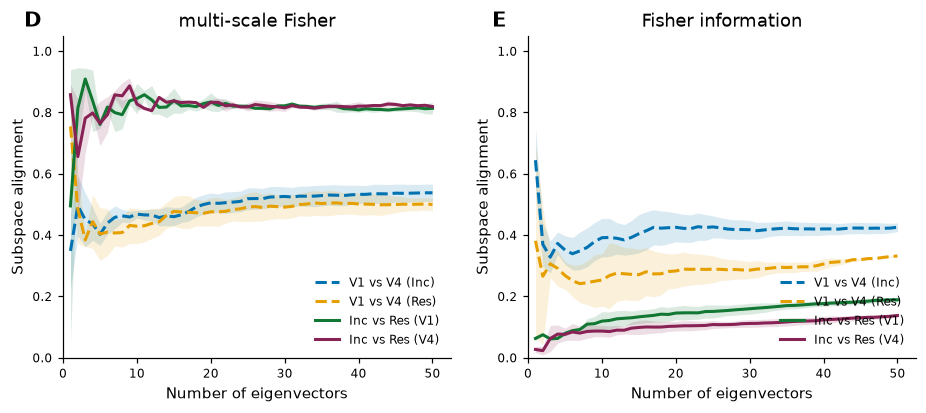

CPU times: user 266 ms, sys: 13.9 ms, total: 280 ms
Wall time: 280 ms


In [6]:
%%time

if metrics_path is None:
    print("Nothing to plot: the alignment needs at least two configurations (see the message above).")
else:
    show_figure(plot_alignment(metrics_path))